In [1]:
# Install required libraries
!pip install torch torchvision timm pandas numpy matplotlib seaborn scikit-learn pillow tqdm albumentations opencv-python

# Import libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
import timm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Check GPU availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 3.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.4/110.4 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 71.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 369.4/369.4 kB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.0/67.0 MB 21.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.0/54.0 MB 27.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 56.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 844.5/844.5 kB 50.8 MB/s eta 0:00:00
Using device: cpu


In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Update these paths according to your Google Drive structure
BASE_PATH = '/content/drive/MyDrive/logoDetection/'  # Adjusted
CSV_PATH = BASE_PATH + 'file_mapping.csv'

# Load the CSV
df = pd.read_csv(CSV_PATH)

# Display dataset info
print("Dataset Shape:", df.shape)
print("\nFirst few rows:")
print(df.head())
print("\nColumn names:")
print(df.columns.tolist())
print("\nLabel distribution:")
print(df['Label'].value_counts())
print("\nBrand distribution:")
print(df['Brand Name'].value_counts())

Mounted at /content/drive
Dataset Shape: (825, 4)

First few rows:
                         Filename   Brand Name    Label  \
0       output\Cowbell\000001.jpg      Cowbell  Genuine   
1  genLogoOutput\Rolex\000003.jpg        Rolex     Fake   
2   output\PlayStation\000005.jpg  PlayStation  Genuine   
3       output\YouTube\000004.jpg      YouTube  Genuine   
4   genLogoOutput\Lays\000004.jpg         Lays     Fake   

                                             Tagline  
0                            sooo creamy sooo gooood  
1  antiophthalmic_factor crown for every accompli...  
2                                        eNoS Lives.  
3                                 Broadcast Yourself  
4                               eNoS sprightliness .  

Column names:
['Filename', 'Brand Name', 'Label', 'Tagline']

Label distribution:
Label
Fake       550
Genuine    275
Name: count, dtype: int64

Brand distribution:
Brand Name
PlayStation    15
Lays           15
YouTube        15
Amazon         15

Missing files: 0

Total brands: 63
Total images: 825

Fake: 550
Original: 275


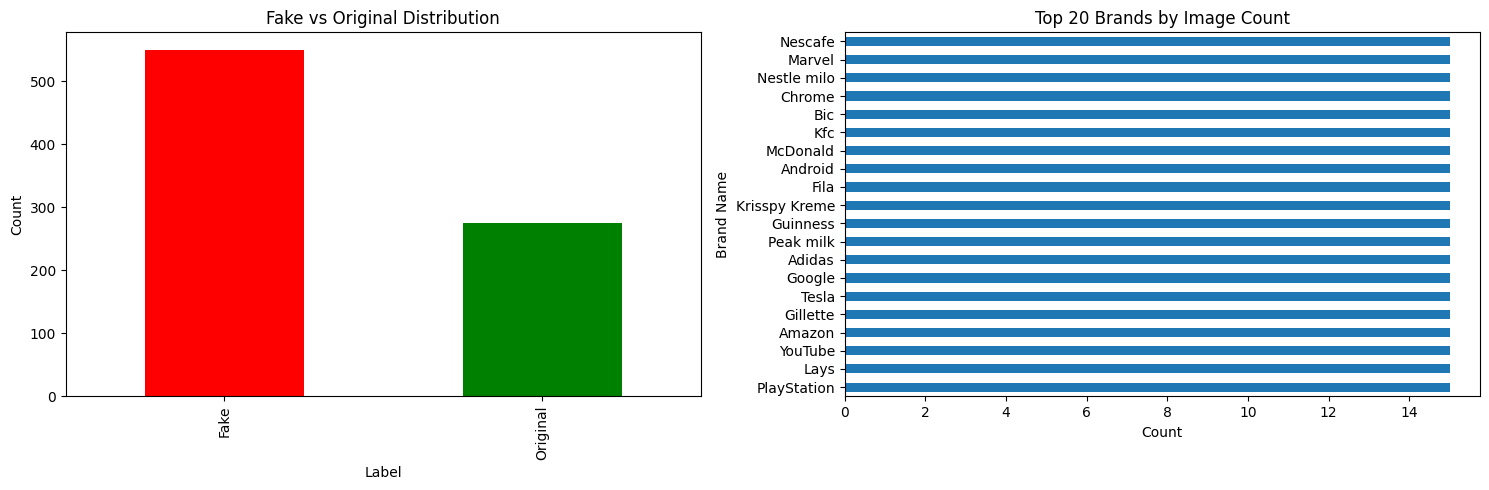

In [3]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# ------------------------------
# 1. Load CSV
# ------------------------------
csv_path = "/content/drive/MyDrive/logoDetection/file_mapping.csv"
df = pd.read_csv(csv_path)

# ------------------------------
# 2. Convert Windows slashes → Linux
# ------------------------------
df["Filename"] = df["Filename"].str.replace("\\", "/", regex=False)

# ------------------------------
# 3. Folder path containing output/ and genLogoOutput/
# ------------------------------
BASE_PATH = "/content/drive/MyDrive/logoDetection/"

# ------------------------------
# 4. Create absolute paths
# ------------------------------
df["Full_Path"] = df["Filename"].apply(lambda x: os.path.join(BASE_PATH, x))

# ------------------------------
# 5. Check file existence
# ------------------------------
df["Exists"] = df["Full_Path"].apply(os.path.exists)
print("Missing files:", (~df["Exists"]).sum())

# Keep only existing ones
df = df[df["Exists"]].reset_index(drop=True)

# ------------------------------
# 6. Fix label naming
# CSV uses:  Fake / Genuine
# Model expects: Fake / Original
# ------------------------------
df["Label"] = df["Label"].replace({"Genuine": "Original"})

# ------------------------------
# 7. Encode Labels → binary
# Fake = 0, Original = 1
# ------------------------------
df["Label_Binary"] = df["Label"].map({"Fake": 0, "Original": 1})

# ------------------------------
# 8. Encode Brand Names
# ------------------------------
brand_encoder = LabelEncoder()
df["Brand_Encoded"] = brand_encoder.fit_transform(df["Brand Name"])

print("\nTotal brands:", df["Brand Name"].nunique())
print("Total images:", len(df))
print("\nFake:", (df["Label_Binary"] == 0).sum())
print("Original:", (df["Label_Binary"] == 1).sum())

# ------------------------------
# 9. Visualization
# ------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Label distribution (bar chart)
df["Label"].value_counts().plot(kind="bar", ax=axes[0], color=["red", "green"])
axes[0].set_title("Fake vs Original Distribution")
axes[0].set_ylabel("Count")

# Top 20 brands (horizontal bar chart)
df["Brand Name"].value_counts().head(20).plot(kind="barh", ax=axes[1])
axes[1].set_title("Top 20 Brands by Image Count")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()


In [4]:
class LogoDataset(Dataset):
    def __init__(self, dataframe, transform=None, task='authenticity'):
        """
        task: 'authenticity' (fake/original) or 'brand' (brand classification)
        """
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform
        self.task = task

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.loc[idx, 'Full_Path']

        # Load image
        try:
            image = Image.open(img_path).convert('RGB')
        except Exception as e:
            print(f"Error loading {img_path}: {e}")
            # Return a blank image if error
            image = Image.new('RGB', (224, 224), color='white')

        if self.transform:
            image = self.transform(image)

        # Return label based on task
        if self.task == 'authenticity':
            label = int(self.df.loc[idx, 'Label_Binary'])
        else:  # brand classification
            label = int(self.df.loc[idx, 'Brand_Encoded'])

        return image, torch.tensor(label, dtype=torch.long)

In [5]:
# Advanced augmentation for training
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

# Validation/Test transforms (no augmentation)
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [6]:
# Stratified split to maintain class distribution
train_df, temp_df = train_test_split(
    df,
    test_size=0.3,
    stratify=df['Label_Binary'],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['Label_Binary'],
    random_state=42
)

print(f"Train size: {len(train_df)}")
print(f"Validation size: {len(val_df)}")
print(f"Test size: {len(test_df)}")

# Create datasets
train_dataset = LogoDataset(train_df, transform=train_transform, task='authenticity')
val_dataset = LogoDataset(val_df, transform=val_transform, task='authenticity')
test_dataset = LogoDataset(test_df, transform=val_transform, task='authenticity')

# Create dataloaders
BATCH_SIZE = 32

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

Train size: 577
Validation size: 124
Test size: 124


In [7]:
class FakeLogoDetector(nn.Module):
    def __init__(self, num_classes=2, pretrained=True):
        super(FakeLogoDetector, self).__init__()

        # Using EfficientNet-B3 (best balance of accuracy and speed)
        self.backbone = timm.create_model('efficientnet_b3', pretrained=pretrained)

        # Get number of features
        num_features = self.backbone.classifier.in_features

        # Replace classifier with custom head
        self.backbone.classifier = nn.Identity()

        # Custom classification head with dropout
        self.classifier = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        features = self.backbone(x)
        output = self.classifier(features)
        return output

# Initialize model
model = FakeLogoDetector(num_classes=2, pretrained=True)
model = model.to(device)

print(model)

model.safetensors:   0%|          | 0.00/49.3M [00:00<?, ?B/s]

FakeLogoDetector(
  (backbone): EfficientNet(
    (conv_stem): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
          (bn1): BatchNormAct2d(
            40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv

In [8]:
# Loss function (with class weights for imbalanced data)
fake_count = (df['Label_Binary'] == 0).sum()
original_count = (df['Label_Binary'] == 1).sum()
total = len(df)

# Calculate class weights
weight_fake = total / (2 * fake_count)
weight_original = total / (2 * original_count)
class_weights = torch.tensor([weight_fake, weight_original], dtype=torch.float32).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

# Optimizer with weight decay
optimizer = optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.01)

# Learning rate scheduler
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=3
)

# Early stopping
class EarlyStopping:
    def __init__(self, patience=7, min_delta=0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None:
            self.best_loss = val_loss
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.counter = 0

early_stopping = EarlyStopping(patience=7)

In [9]:
print(f"Class weights dtype: {class_weights.dtype}")  # Should be torch.float32

Class weights dtype: torch.float32


In [10]:
def train_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    progress_bar = tqdm(dataloader, desc='Training')

    for images, labels in progress_bar:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()
        optimizer.step()

        # Statistics
        running_loss += loss.item()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        progress_bar.set_postfix({'loss': loss.item(), 'acc': 100 * correct / total})

    epoch_loss = running_loss / len(dataloader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

def validate_epoch(model, dataloader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(dataloader, desc='Validation'):
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / len(dataloader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

# Training
NUM_EPOCHS = 30
best_val_acc = 0.0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(NUM_EPOCHS):
    print(f"\nEpoch {epoch+1}/{NUM_EPOCHS}")
    print("-" * 50)

    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, device)

    # Validate
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)

    # Update scheduler
    scheduler.step(val_loss)

    # Save history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
    print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_acc': val_acc,
            'val_loss': val_loss
        }, BASE_PATH + 'best_fake_logo_detector.pth')
        print(f"✅ Model saved with Val Acc: {val_acc:.2f}%")

    # Early stopping
    early_stopping(val_loss)
    if early_stopping.early_stop:
        print("Early stopping triggered!")
        break

print(f"\n🎉 Training completed! Best Val Acc: {best_val_acc:.2f}%")


Epoch 1/30
--------------------------------------------------


Validation: 100%|██████████| 4/4 [00:24<00:00,  6.04s/it]


Train Loss: 0.6782, Train Acc: 65.34%
Val Loss: 0.4926, Val Acc: 87.10%
✅ Model saved with Val Acc: 87.10%

Epoch 2/30
--------------------------------------------------


Validation: 100%|██████████| 4/4 [00:08<00:00,  2.12s/it]


Train Loss: 0.2906, Train Acc: 90.99%
Val Loss: 0.7662, Val Acc: 79.03%

Epoch 3/30
--------------------------------------------------


...

Train Loss: 0.0431, Train Acc: 99.31%
Val Loss: 0.0938, Val Acc: 95.97%

Epoch 28/30
--------------------------------------------------


Validation: 100%|██████████| 4/4 [00:08<00:00,  2.09s/it]


Train Loss: 0.0468, Train Acc: 99.31%
Val Loss: 0.1251, Val Acc: 94.35%

Epoch 29/30
--------------------------------------------------


Validation: 100%|██████████| 4/4 [00:08<00:00,  2.04s/it]

Train Loss: 0.0090, Train Acc: 100.00%
Val Loss: 0.1880, Val Acc: 93.55%
Early stopping triggered!

🎉 Training completed! Best Val Acc: 99.19%


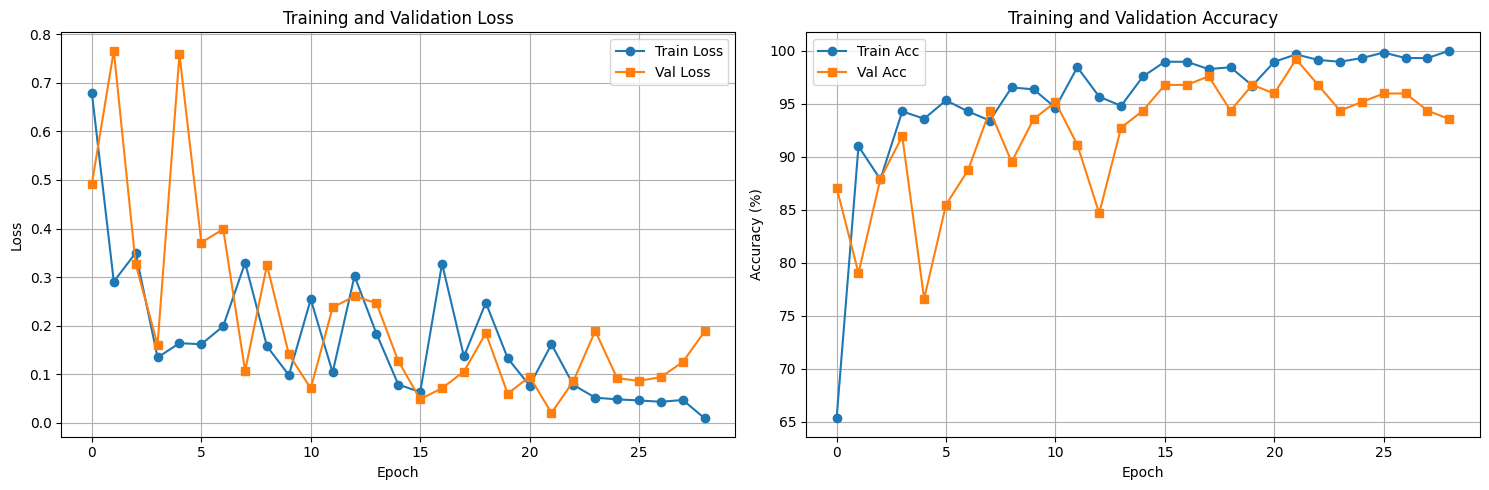

In [12]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left subplot - Loss
axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)

# Right subplot - Accuracy
axes[1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[1].plot(history['val_acc'], label='Val Acc', marker='s')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig(BASE_PATH + 'training_history.png', dpi=300, bbox_inches='tight')
plt.show()

Testing: 100%|██████████| 4/4 [00:26<00:00,  6.60s/it]



📊 TEST SET RESULTS
Accuracy: 97.58%
F1-Score: 0.9760

Classification Report:
              precision    recall  f1-score   support

        Fake       1.00      0.96      0.98        83
    Original       0.93      1.00      0.96        41

    accuracy                           0.98       124
   macro avg       0.97      0.98      0.97       124
weighted avg       0.98      0.98      0.98       124



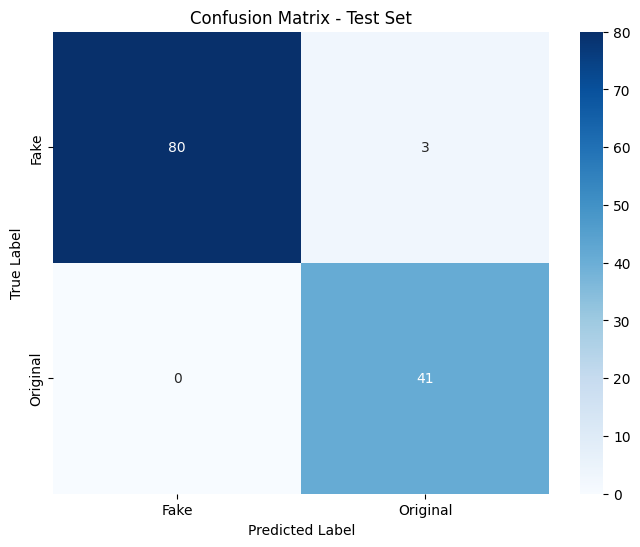

In [13]:
# Load best model
checkpoint = torch.load(BASE_PATH + 'best_fake_logo_detector.pth')
model.load_state_dict(checkpoint['model_state_dict'])

# Evaluate
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Testing'):
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate metrics
test_acc = accuracy_score(all_labels, all_preds)
test_f1 = f1_score(all_labels, all_preds, average='weighted')

print(f"\n{'='*50}")
print(f"📊 TEST SET RESULTS")
print(f"{'='*50}")
print(f"Accuracy: {test_acc*100:.2f}%")
print(f"F1-Score: {test_f1:.4f}")
print(f"\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=['Fake', 'Original']))

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Fake', 'Original'],
            yticklabels=['Fake', 'Original'])
plt.title('Confusion Matrix - Test Set')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.savefig(BASE_PATH + 'confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

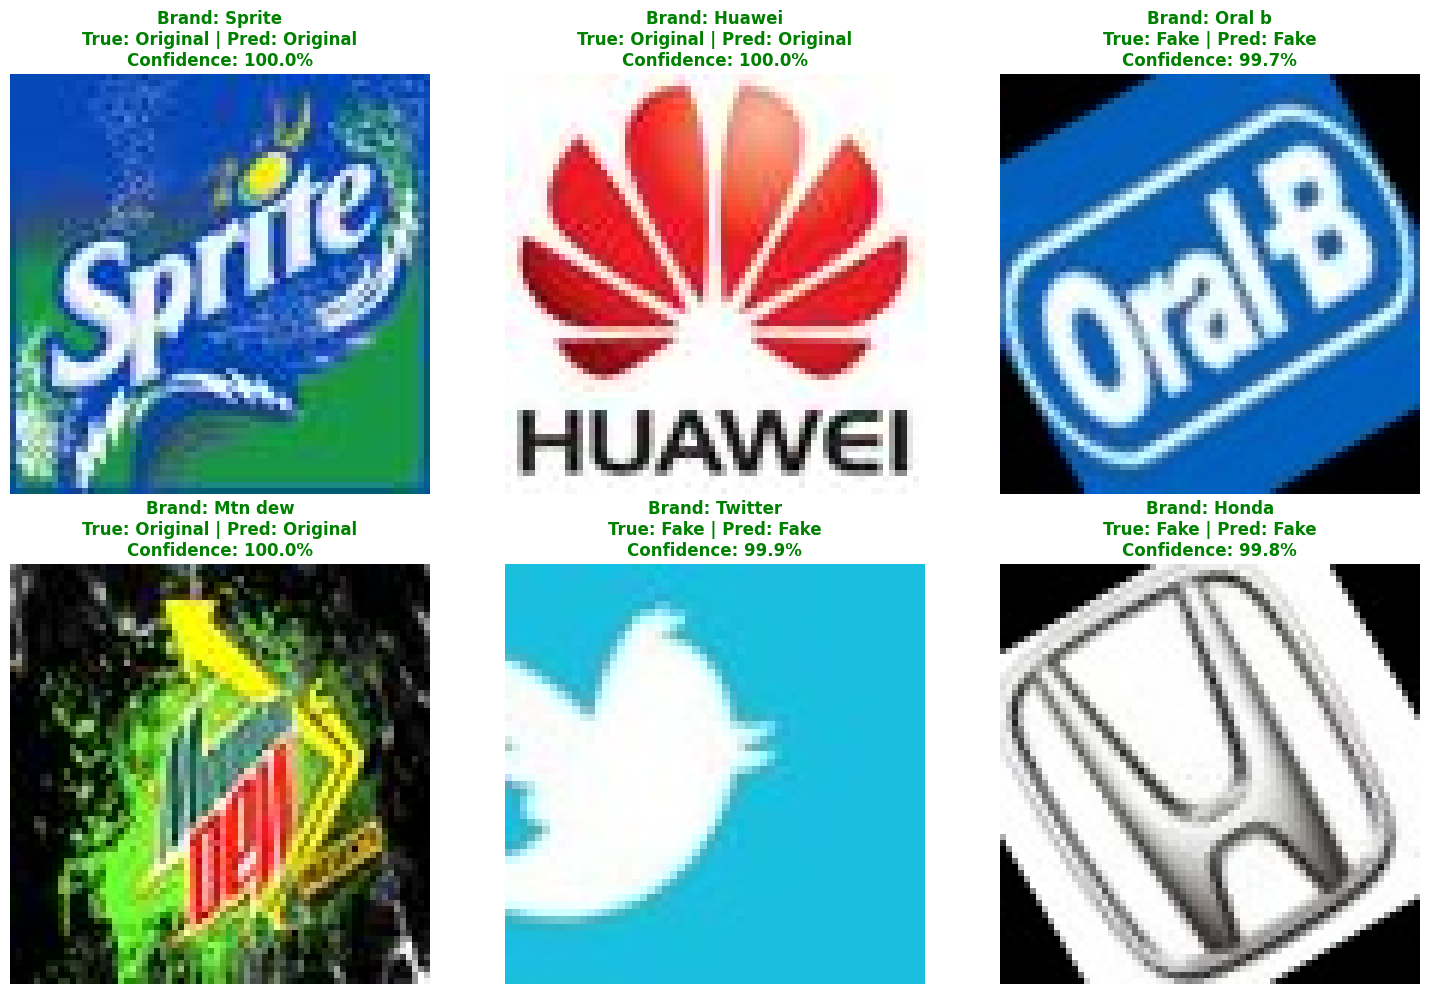

In [14]:
def predict_logo(image_path, model, device, transform):
    """
    Predict if a logo is fake or original
    """
    model.eval()

    # Load and preprocess image
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)

    # Predict
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)
        confidence, predicted = torch.max(probabilities, 1)

    label = 'Fake' if predicted.item() == 0 else 'Original'
    confidence = confidence.item() * 100

    return label, confidence

# Test on random images
import random
sample_indices = random.sample(range(len(test_df)), 6)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()

for idx, sample_idx in enumerate(sample_indices):
    img_path = test_df.iloc[sample_idx]['Full_Path']
    true_label = 'Fake' if test_df.iloc[sample_idx]['Label_Binary'] == 0 else 'Original'
    brand = test_df.iloc[sample_idx]['Brand Name']

    pred_label, confidence = predict_logo(img_path, model, device, val_transform)

    # Display
    img = Image.open(img_path)
    axes[idx].imshow(img)
    axes[idx].axis('off')

    color = 'green' if pred_label == true_label else 'red'
    axes[idx].set_title(f"Brand: {brand}\nTrue: {true_label} | Pred: {pred_label}\nConfidence: {confidence:.1f}%",
                        color=color, fontweight='bold')

plt.tight_layout()
plt.savefig(BASE_PATH + 'sample_predictions.png', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
import torch

# Save the model's state dictionary
torch.save(model.state_dict(), 'logo_detection_model.pth')
print("Model saved successfully as 'logo_detection_model.pth'")

Model saved successfully as 'logo_detection_model.pth'


In [18]:
from google.colab import files
files.download('logo_detection_model.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>